<a href="https://colab.research.google.com/github/GunjanBalapure/Gen_AI_Lab/blob/main/Research%20Paper%20Implementation/02_Implementation/DCGAN_Fashion_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# ==========================================
# DCGAN: Fashion-MNIST Image Generation
# Research Paper Implementation
# ==========================================

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt

import os
import random

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Check whether GPU is available

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected Device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Running on CPU.")

Selected Device: cuda
GPU Name: Tesla T4


In [6]:
# Reproducibility

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# DCGAN Configuration

IMAGE_SIZE = 28
CHANNELS = 1
LATENT_DIM = 100

BATCH_SIZE = 128
EPOCHS = 20

LEARNING_RATE = 0.0002
BETA1 = 0.5

print("Experiment configuration completed!")

Experiment configuration completed!


In [7]:
# ==========================================
# STEP 1: LOAD FASHION-MNIST DATASET
# ==========================================

# Convert images to tensors and normalize
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Download and load training dataset
train_dataset = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Create DataLoader
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Fashion-MNIST dataset loaded successfully!")
print("Total training images:", len(train_dataset))
print("Batch size:", BATCH_SIZE)
print("Number of batches:", len(train_loader))

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 201kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 4.25MB/s]

Fashion-MNIST dataset loaded successfully!
Total training images: 60000
Batch size: 128
Number of batches: 469


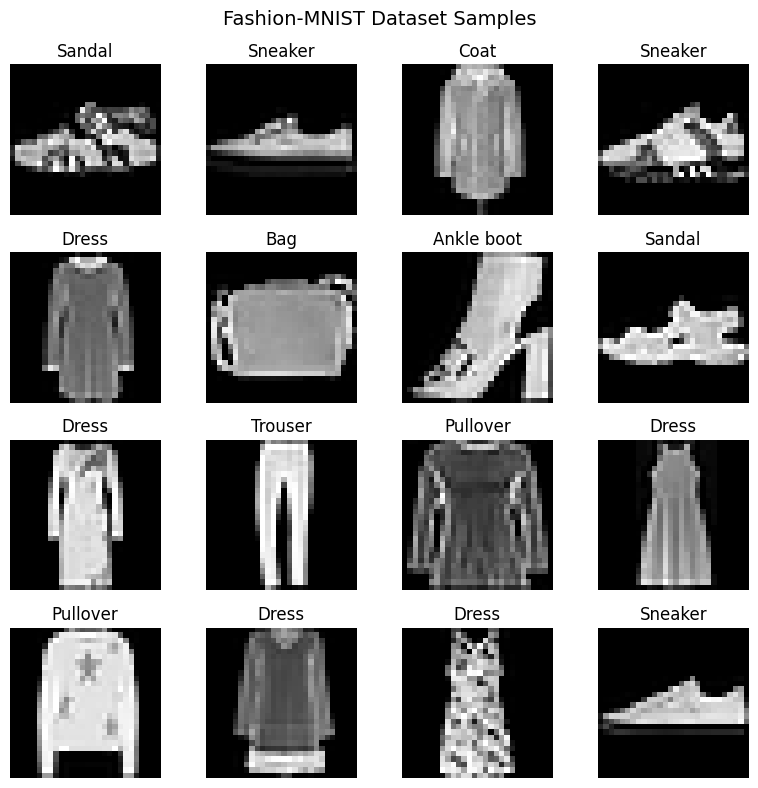

In [8]:
# ==========================================
# STEP 2: VISUALIZE FASHION-MNIST IMAGES
# ==========================================

# Fashion-MNIST class names
classes = [
    'T-shirt/top', 'Trouser', 'Pullover',
    'Dress', 'Coat', 'Sandal', 'Shirt',
    'Sneaker', 'Bag', 'Ankle boot'
]

# Get one batch of images
images, labels = next(iter(train_loader))

# Display 16 images
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):

    # Convert image from [-1, 1] to [0, 1]
    image = images[i].squeeze() * 0.5 + 0.5

    ax.imshow(image, cmap='gray')
    ax.set_title(classes[labels[i].item()])
    ax.axis('off')

plt.suptitle("Fashion-MNIST Dataset Samples", fontsize=14)
plt.tight_layout()
plt.show()

In [9]:
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Image minimum:", images.min().item())
print("Image maximum:", images.max().item())

Image batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])
Image minimum: -1.0
Image maximum: 1.0


In [10]:
# ==========================================
# STEP 3: BUILD THE GENERATOR
# ==========================================

class Generator(nn.Module):

    def __init__(self, latent_dim):

        super(Generator, self).__init__()

        self.model = nn.Sequential(

            # Layer 1: Noise -> 7x7 feature maps
            nn.ConvTranspose2d(
                latent_dim, 256,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            # Layer 2: 7x7 -> 14x14
            nn.ConvTranspose2d(
                256, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # Layer 3: 14x14 -> 28x28
            nn.ConvTranspose2d(
                128, CHANNELS,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),

            # Output between -1 and +1
            nn.Tanh()
        )

    def forward(self, noise):

        return self.model(noise)


# Create Generator instance
generator = Generator(LATENT_DIM).to(device)

print("Generator created successfully!")

print(generator)

Generator created successfully!
Generator(
  (model): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): Tanh()
  )
)


In [11]:
# ==========================================
# STEP 4: TEST THE GENERATOR
# ==========================================

# Generate random noise
sample_noise = torch.randn(
    16, LATENT_DIM, 1, 1,
    device=device
)

# Generate fake images
with torch.no_grad():
    generated_images = generator(sample_noise)

print("Generated image shape:", generated_images.shape)
print("Minimum pixel value:", generated_images.min().item())
print("Maximum pixel value:", generated_images.max().item())

Generated image shape: torch.Size([16, 1, 28, 28])
Minimum pixel value: -0.9999999403953552
Maximum pixel value: 0.9999998211860657


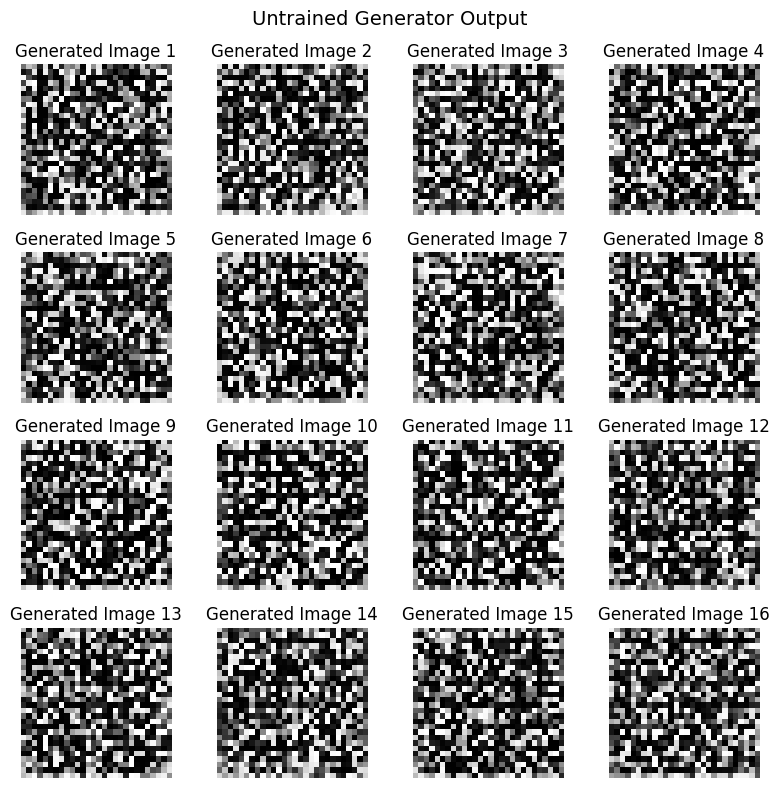

In [12]:
# ==========================================
# STEP 5: VISUALIZE INITIAL GENERATED IMAGES
# ==========================================

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):

    image = generated_images[i].squeeze().cpu()

    # Convert [-1, 1] to [0, 1]
    image = image * 0.5 + 0.5

    ax.imshow(image, cmap='gray')
    ax.set_title(f"Generated Image {i+1}")
    ax.axis('off')

plt.suptitle(
    "Untrained Generator Output",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [13]:
# ==========================================
# STEP 6: BUILD THE DISCRIMINATOR
# ==========================================

class Discriminator(nn.Module):

    def __init__(self):

        super(Discriminator, self).__init__()

        self.model = nn.Sequential(

            # Layer 1: 28x28 -> 14x14
            nn.Conv2d(
                CHANNELS, 64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.LeakyReLU(0.2, inplace=True),

            # Layer 2: 14x14 -> 7x7
            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # Layer 3: 7x7 -> 1x1
            nn.Conv2d(
                128, 1,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.Sigmoid()
        )

    def forward(self, image):

        return self.model(image).view(-1, 1)


# Create Discriminator instance
discriminator = Discriminator().to(device)

print("Discriminator created successfully!")
print(discriminator)

Discriminator created successfully!
Discriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 1, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (6): Sigmoid()
  )
)


In [14]:
# ==========================================
# STEP 7: TEST THE DISCRIMINATOR
# ==========================================

# Test with real images
real_images = images.to(device)

# Test with generated images
noise = torch.randn(
    BATCH_SIZE, LATENT_DIM, 1, 1,
    device=device
)

with torch.no_grad():
    fake_images = generator(noise)

    real_predictions = discriminator(real_images)
    fake_predictions = discriminator(fake_images)

print("Real prediction shape:", real_predictions.shape)
print("Fake prediction shape:", fake_predictions.shape)

print("Average real prediction:",
      real_predictions.mean().item())

print("Average fake prediction:",
      fake_predictions.mean().item())

Real prediction shape: torch.Size([128, 1])
Fake prediction shape: torch.Size([128, 1])
Average real prediction: 0.5458393096923828
Average fake prediction: 0.5542343854904175


In [15]:
# ==========================================
# STEP 8: INITIALIZE MODEL WEIGHTS
# ==========================================

def weights_init(model):

    classname = model.__class__.__name__

    if classname.find('Conv') != -1:

        nn.init.normal_(
            model.weight.data,
            0.0,
            0.02
        )

    elif classname.find('BatchNorm') != -1:

        nn.init.normal_(
            model.weight.data,
            1.0,
            0.02
        )

        nn.init.constant_(
            model.bias.data,
            0
        )


# Apply initialization
generator.apply(weights_init)
discriminator.apply(weights_init)

print("Generator weights initialized!")
print("Discriminator weights initialized!")

Generator weights initialized!
Discriminator weights initialized!


In [16]:
# ==========================================
# STEP 9: DEFINE LOSS FUNCTION
# ==========================================

criterion = nn.BCELoss()

print("Binary Cross Entropy Loss initialized!")

Binary Cross Entropy Loss initialized!


In [17]:
# ==========================================
# STEP 10: DEFINE OPTIMIZERS
# ==========================================

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, 0.999)
)

print("Generator optimizer initialized!")
print("Discriminator optimizer initialized!")

Generator optimizer initialized!
Discriminator optimizer initialized!


In [18]:
# ==========================================
# STEP 11: PREPARE TRAINING VARIABLES
# ==========================================

# Fixed noise for monitoring image generation
fixed_noise = torch.randn(
    16, LATENT_DIM, 1, 1,
    device=device
)

# Real and fake labels
real_label = 1.0
fake_label = 0.0

# Store losses for analysis
G_losses = []
D_losses = []

print("Training variables prepared!")
print("Fixed noise shape:", fixed_noise.shape)

Training variables prepared!
Fixed noise shape: torch.Size([16, 100, 1, 1])


In [19]:
# ==========================================
# STEP 12: DCGAN ADVERSARIAL TRAINING
# ==========================================

from tqdm.auto import tqdm

# Directory to save generated images
os.makedirs("generated_images", exist_ok=True)

print("Starting DCGAN Training...")

for epoch in range(EPOCHS):

    total_G_loss = 0
    total_D_loss = 0

    for real_images, _ in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):

        real_images = real_images.to(device)

        current_batch_size = real_images.size(0)

        # Create labels
        real_labels = torch.ones(
            current_batch_size, 1,
            device=device
        )

        fake_labels = torch.zeros(
            current_batch_size, 1,
            device=device
        )

        # ==================================
        # PHASE A: TRAIN DISCRIMINATOR
        # ==================================

        optimizer_D.zero_grad()

        # Classify real images
        real_output = discriminator(real_images)

        loss_real = criterion(
            real_output,
            real_labels
        )

        # Generate fake images
        noise = torch.randn(
            current_batch_size,
            LATENT_DIM, 1, 1,
            device=device
        )

        fake_images = generator(noise)

        # Classify fake images
        fake_output = discriminator(
            fake_images.detach()
        )

        loss_fake = criterion(
            fake_output,
            fake_labels
        )

        # Total discriminator loss
        loss_D = loss_real + loss_fake

        loss_D.backward()
        optimizer_D.step()

        # ==================================
        # PHASE B: TRAIN GENERATOR
        # ==================================

        optimizer_G.zero_grad()

        # Generator tries to fool discriminator
        output = discriminator(fake_images)

        loss_G = criterion(
            output,
            real_labels
        )

        loss_G.backward()
        optimizer_G.step()

        total_D_loss += loss_D.item()
        total_G_loss += loss_G.item()

    # Calculate average losses
    avg_D_loss = total_D_loss / len(train_loader)
    avg_G_loss = total_G_loss / len(train_loader)

    D_losses.append(avg_D_loss)
    G_losses.append(avg_G_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Generator Loss: {avg_G_loss:.4f} | "
        f"Discriminator Loss: {avg_D_loss:.4f}"
    )

    # Generate images using fixed noise
    generator.eval()

    with torch.no_grad():
        sample_images = generator(fixed_noise)

    generator.train()

    # Save generated images
    torchvision.utils.save_image(
        sample_images,
        f"generated_images/epoch_{epoch+1}.png",
        normalize=True,
        nrow=4
    )

print("\nDCGAN Training Completed!")

Starting DCGAN Training...


Epoch 1/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch [1/20] Generator Loss: 1.6706 | Discriminator Loss: 0.6951


Epoch 2/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch [2/20] Generator Loss: 1.7227 | Discriminator Loss: 0.6519


Epoch 3/20:   0%|          | 0/469 [00:00<?, ?it/s]

... (43 outputs left out)

Epoch [19/20] Generator Loss: 1.0817 | Discriminator Loss: 1.1885


Epoch 20/20:   0%|          | 0/469 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d3c95097a60>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7d3c95097a60>Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()    
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
self._shutdown_workers()
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
if w.is_alive():
    if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/lib/python3.13/multiprocessing/process.py", line 16

Epoch [20/20] Generator Loss: 1.0736 | Discriminator Loss: 1.1920

DCGAN Training Completed!


In [20]:
# ==========================================
# STEP 12: DCGAN ADVERSARIAL TRAINING
# ==========================================

from tqdm.auto import tqdm

# Directory to save generated images
os.makedirs("generated_images", exist_ok=True)

print("Starting DCGAN Training...")

for epoch in range(EPOCHS):

    total_G_loss = 0
    total_D_loss = 0

    for real_images, _ in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):

        real_images = real_images.to(device)

        current_batch_size = real_images.size(0)

        # Create labels
        real_labels = torch.ones(
            current_batch_size, 1,
            device=device
        )

        fake_labels = torch.zeros(
            current_batch_size, 1,
            device=device
        )

        # ==================================
        # PHASE A: TRAIN DISCRIMINATOR
        # ==================================

        optimizer_D.zero_grad()

        # Classify real images
        real_output = discriminator(real_images)

        loss_real = criterion(
            real_output,
            real_labels
        )

        # Generate fake images
        noise = torch.randn(
            current_batch_size,
            LATENT_DIM, 1, 1,
            device=device
        )

        fake_images = generator(noise)

        # Classify fake images
        fake_output = discriminator(
            fake_images.detach()
        )

        loss_fake = criterion(
            fake_output,
            fake_labels
        )

        # Total discriminator loss
        loss_D = loss_real + loss_fake

        loss_D.backward()
        optimizer_D.step()

        # ==================================
        # PHASE B: TRAIN GENERATOR
        # ==================================

        optimizer_G.zero_grad()

        # Generator tries to fool discriminator
        output = discriminator(fake_images)

        loss_G = criterion(
            output,
            real_labels
        )

        loss_G.backward()
        optimizer_G.step()

        total_D_loss += loss_D.item()
        total_G_loss += loss_G.item()

    # Calculate average losses
    avg_D_loss = total_D_loss / len(train_loader)
    avg_G_loss = total_G_loss / len(train_loader)

    D_losses.append(avg_D_loss)
    G_losses.append(avg_G_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Generator Loss: {avg_G_loss:.4f} | "
        f"Discriminator Loss: {avg_D_loss:.4f}"
    )

    # Generate images using fixed noise
    generator.eval()

    with torch.no_grad():
        sample_images = generator(fixed_noise)

    generator.train()

    # Save generated images
    torchvision.utils.save_image(
        sample_images,
        f"generated_images/epoch_{epoch+1}.png",
        normalize=True,
        nrow=4
    )

print("\nDCGAN Training Completed!")

Starting DCGAN Training...


Epoch 1/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch [1/20] Generator Loss: 1.0672 | Discriminator Loss: 1.1999


Epoch 2/20:   0%|          | 0/469 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d3c95097a60>
Exception ignored in: Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7d3c95097a60>Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

<function _MultiProcessingDataLoaderIter.__del__ at 0x7d3c95097a60>Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    
self._shutdown_workers()    
Traceback (most recent call last):
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
if w.is_alive():self._sh

Epoch [2/20] Generator Loss: 1.0683 | Discriminator Loss: 1.2037


... (45 outputs left out)

Epoch 19/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch [19/20] Generator Loss: 1.0256 | Discriminator Loss: 1.2273


Epoch 20/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch [20/20] Generator Loss: 1.0294 | Discriminator Loss: 1.2243

DCGAN Training Completed!


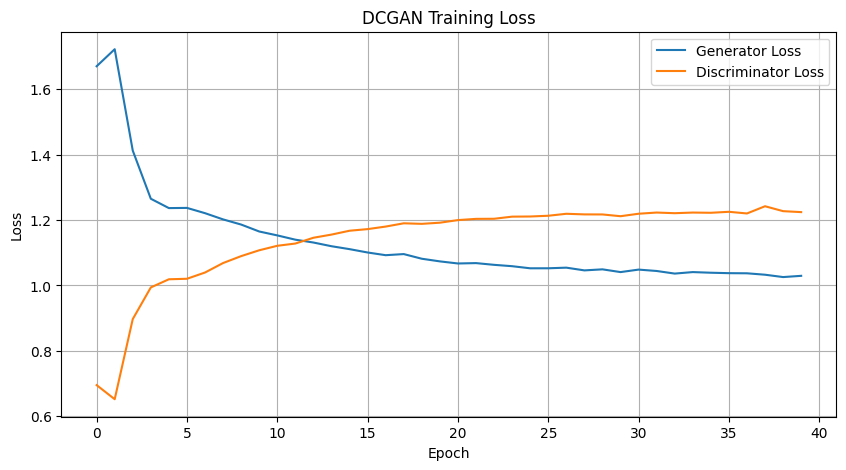

In [21]:
# ==========================================
# STEP 13: PLOT TRAINING LOSSES
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    G_losses,
    label="Generator Loss"
)

plt.plot(
    D_losses,
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("DCGAN Training Loss")

plt.legend()
plt.grid(True)

plt.savefig(
    "generated_images/training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

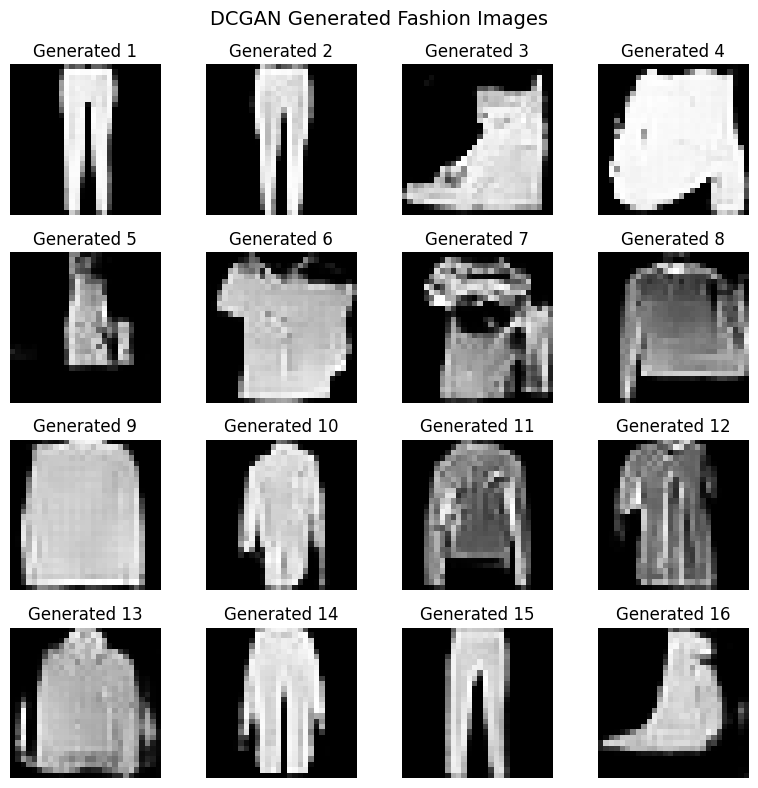

In [22]:
# ==========================================
# STEP 14: FINAL IMAGE GENERATION
# ==========================================

generator.eval()

with torch.no_grad():

    final_images = generator(fixed_noise)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):

    image = final_images[i].squeeze().cpu()

    image = image * 0.5 + 0.5

    ax.imshow(image, cmap="gray")

    ax.set_title(f"Generated {i+1}")

    ax.axis("off")

plt.suptitle(
    "DCGAN Generated Fashion Images",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "generated_images/final_generated_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

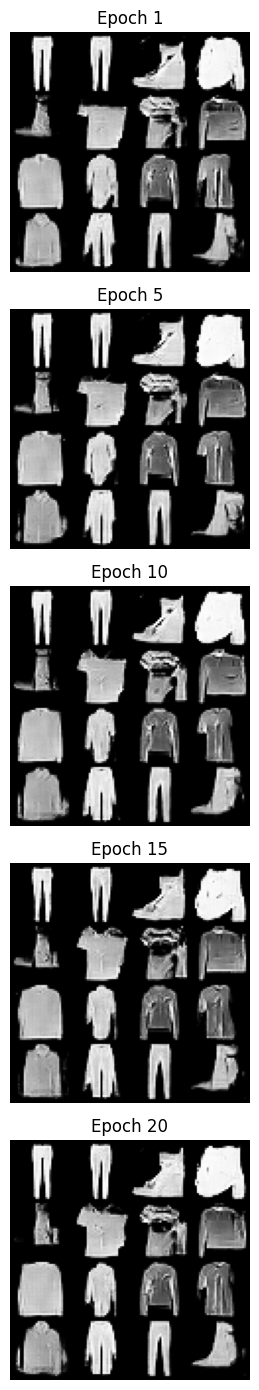

In [23]:
# ==========================================
# STEP 15: COMPARE TRAINING EPOCHS
# ==========================================

from PIL import Image

selected_epochs = [1, 5, 10, 15, 20]

fig, axes = plt.subplots(
    len(selected_epochs), 1,
    figsize=(8, 14)
)

for i, epoch in enumerate(selected_epochs):

    img = Image.open(
        f"generated_images/epoch_{epoch}.png"
    )

    axes[i].imshow(img, cmap="gray")

    axes[i].set_title(f"Epoch {epoch}")

    axes[i].axis("off")

plt.tight_layout()

plt.show()

In [24]:
print("Configured epochs:", EPOCHS)
print("Recorded Generator epochs:", len(G_losses))
print("Recorded Discriminator epochs:", len(D_losses))

Configured epochs: 20
Recorded Generator epochs: 40
Recorded Discriminator epochs: 40


In [25]:
# Save trained DCGAN models

os.makedirs("saved_models", exist_ok=True)

torch.save(
    generator.state_dict(),
    "saved_models/dcgan_generator.pth"
)

torch.save(
    discriminator.state_dict(),
    "saved_models/dcgan_discriminator.pth"
)

print("Both trained models saved successfully!")

Both trained models saved successfully!


In [26]:
# ==========================================
# STEP 16: ORGANIZE EXPERIMENTAL RESULTS
# ==========================================

import shutil
import os

os.makedirs("DCGAN_Results", exist_ok=True)

# Copy generated images and graphs
shutil.copytree(
    "generated_images",
    "DCGAN_Results/generated_images",
    dirs_exist_ok=True
)

# Copy trained model weights
shutil.copytree(
    "saved_models",
    "DCGAN_Results/saved_models",
    dirs_exist_ok=True
)

# Create ZIP archive
shutil.make_archive(
    "DCGAN_Results",
    "zip",
    "DCGAN_Results"
)

print("Results packaged successfully!")

Results packaged successfully!


In [27]:
from google.colab import files

files.download("DCGAN_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>